In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],goal - abs(goal-result))

### learner rewards

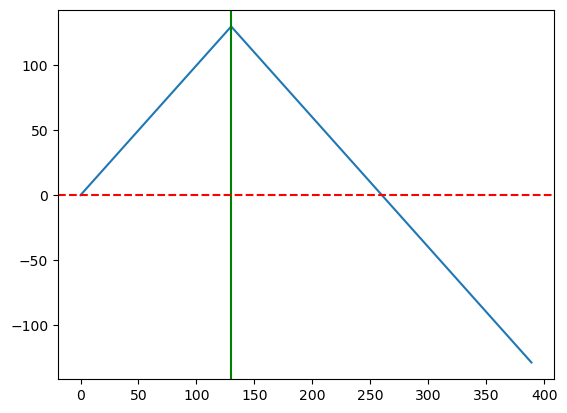

In [4]:
values=[]
goal=130
for i in range(goal*3):
    values.append(goal-abs(goal-i))
plt.plot(values)
plt.axvline(x= goal,color ='g')
plt.axhline(y= 0,color ='r',linestyle = "dashed")

### Test

In [5]:
episodeNumber=30000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
episodesTestResultsDeviation=[]
numberOfTest=50
qagent= Qlearning(0.1,0.99,0.1,2)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [6]:
goal=130

In [7]:
for episodeIndex in range(episodeNumber):
    
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            #if(episodeIndex %500 ==0):
                #episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)


    if(episodeIndex %500 ==0):
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/numberOfTest)
        episodesTestResultsDeviation.append(np.std(episodesTestResults))
        qagent.epsilon=0.1
    


env.close() 

118.92873333333333


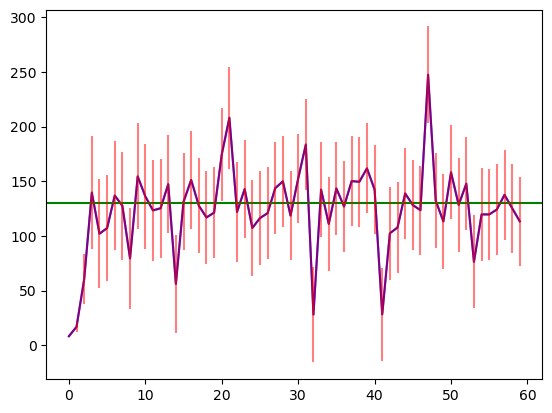

In [8]:
plt.plot(episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(range(len(episodesTestResults)),episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
print(sum(episodesResults)/len(episodesResults))

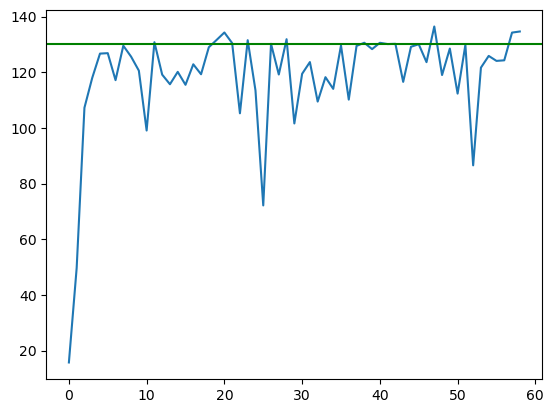

In [9]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)
plt.axhline(y= goal,color ='g')

1088


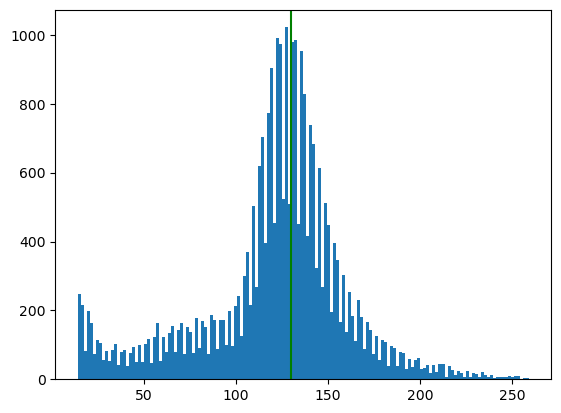

In [12]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
print(len(episodesResults)-len(episodesResultswithoutOutliers))

In [11]:
goal1LearnerEp=episodesResults
%store goal1LearnerEp
goal1learnerTestEp=episodesTestResults
%store goal1learnerTestEp

Stored 'goal1LearnerEp' (list)
Stored 'goal1learnerTestEp' (list)
